# E-commerce Marketplace: What Late Deliveries Cost in Customer Reviews

**Business problem:** online marketplaces promise a delivery date at checkout. When the parcel arrives late, the customer blames the marketplace, not the courier, and the review score that drives future sales takes the hit. How often are deliveries late, how much does lateness hurt reviews, and where and when does it happen?

**Data:** the Olist public dataset: about 99,000 orders placed on Brazil's largest department-store marketplace between September 2016 and October 2018. Three related tables are used: `orders` (status and timestamps, including the promised date), `reviews` (1 to 5 stars) and `customers` (state). Licence: CC BY-NC-SA 4.0.

**Tools:** SQL (SQLite, joins and window functions), Python (pandas, matplotlib).

In [1]:
import json, os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 12,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
os.makedirs("images", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("data", exist_ok=True)

import re, sqlite3
BASE = "https://raw.githubusercontent.com/olist/work-at-olist-data/master/datasets/"
FILES = {"orders": "olist_orders_dataset.csv", "reviews": "olist_order_reviews_dataset.csv", "customers": "olist_customers_dataset.csv"}
for f in FILES.values():
    if not os.path.exists(f"data/{f}"):
        urllib.request.urlretrieve(BASE + f, f"data/{f}")
tables = {name: pd.read_csv(f"data/{f}") for name, f in FILES.items()}
{name: t.shape for name, t in tables.items()}

{'orders': (99441, 8), 'reviews': (99224, 7), 'customers': (99441, 5)}

## 1. Data checks

In [2]:
o, r = tables["orders"], tables["reviews"]
checks = pd.Series({
    "orders": len(o),
    "delivered orders": int((o["order_status"] == "delivered").sum()),
    "delivered but no delivery date": int(((o["order_status"] == "delivered") & o["order_delivered_customer_date"].isna()).sum()),
    "reviews": len(r),
    "orders with more than one review": int((r["order_id"].value_counts() > 1).sum()),
    "duplicate customer IDs": int(tables["customers"]["customer_id"].duplicated().sum()),
})
display(checks)
o["order_status"].value_counts()

orders                              99441
delivered orders                    96478
delivered but no delivery date          8
reviews                             99224
orders with more than one review      547
duplicate customer IDs                  0
dtype: int64

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Delivered orders without a delivery date (8) are excluded. Where an order has several reviews, the latest answer is kept, using a window function in the SQL below.

## 2. Build the analysis table in SQL

In [3]:
con = sqlite3.connect(":memory:")
for name, t in tables.items():
    t.to_sql(name, con, index=False)
sql_text = open("queries.sql").read()
QUERIES = {m.group(1): m.group(2).strip() for m in re.finditer(r"-- name: (\w+)\n(.*?)(?=\n-- name:|\Z)", sql_text, re.S)}
d = pd.read_sql(QUERIES["delivered_orders"], con, parse_dates=["purchase_date"])
d["late"] = d["days_vs_estimate"] > 0
print(d.shape)
d.head()

(96470, 7)


,order_id,customer_state,purchase_date,days_to_deliver,days_vs_estimate,review_score,late
0,e481f51cbdc54678b7cc49136f2d6af7,SP,2017-10-02,8.437,-8,4.000,False
1,53cdb2fc8bc7dce0b6741e2150273451,BA,2018-07-24,13.782,-6,4.000,False
2,47770eb9100c2d0c44946d9cf07ec65d,GO,2018-08-08,9.394,-18,5.000,False
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,2017-11-18,13.209,-13,5.000,False
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,2018-02-13,2.874,-10,5.000,False


## 3. How often are deliveries late, and how much does it matter?

In [4]:
reviewed = d.dropna(subset=["review_score"])
headline = {
    "delivered_orders": len(d),
    "late_orders": int(d["late"].sum()),
    "late_pct": round(100 * d["late"].mean(), 1),
    "median_days_to_deliver": round(d["days_to_deliver"].median(), 1),
    "median_days_early_vs_estimate": int(-d["days_vs_estimate"].median()),
    "avg_review_on_time": round(reviewed.loc[~reviewed["late"], "review_score"].mean(), 2),
    "avg_review_late": round(reviewed.loc[reviewed["late"], "review_score"].mean(), 2),
    "one_star_on_time_pct": round(100 * (reviewed.loc[~reviewed["late"], "review_score"] == 1).mean(), 1),
    "one_star_late_pct": round(100 * (reviewed.loc[reviewed["late"], "review_score"] == 1).mean(), 1),
    "avg_review_all": round(reviewed["review_score"].mean(), 2),
}
# What would the platform's average be if late orders were reviewed like on-time ones?
headline["avg_review_if_never_late"] = headline["avg_review_on_time"]
headline["share_of_one_star_from_late_pct"] = round(100 * ((reviewed["review_score"] == 1) & reviewed["late"]).sum() / (reviewed["review_score"] == 1).sum(), 1)
pd.Series(headline)

delivered_orders                  96,470.000
late_orders                        6,534.000
late_pct                               6.800
median_days_to_deliver                10.200
median_days_early_vs_estimate         12.000
avg_review_on_time                     4.290
avg_review_late                        2.270
one_star_on_time_pct                   6.600
one_star_late_pct                     53.800
avg_review_all                         4.160
avg_review_if_never_late               4.290
share_of_one_star_from_late_pct       36.700
dtype: float64

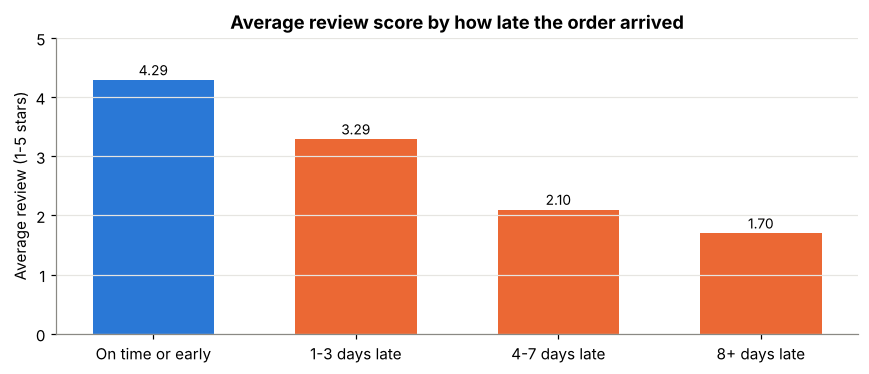

,orders,avg_review,one_star_pct
band,,,
On time or early,89443,4.290,6.620
1-3 days late,1852,3.290,25.110
4-7 days late,1748,2.100,58.580
8+ days late,2781,1.700,69.830


In [5]:
bands = pd.cut(d["days_vs_estimate"], [-1000, 0, 3, 7, 1000], labels=["On time or early", "1-3 days late", "4-7 days late", "8+ days late"])
by_band = (d.assign(band=bands).dropna(subset=["review_score"]).groupby("band", observed=True)
             .agg(orders=("review_score", "size"), avg_review=("review_score", "mean"),
                  one_star_pct=("review_score", lambda s: 100 * (s == 1).mean())).round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(by_band.index.astype(str), by_band["avg_review"], color=[BLUE, ORANGE, ORANGE, ORANGE], width=0.6)
for i, v in enumerate(by_band["avg_review"]):
    ax.text(i, v + 0.08, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylim(0, 5); ax.set_ylabel("Average review (1-5 stars)"); ax.grid(axis="x", visible=False)
ax.set_title("Average review score by how late the order arrived")
fig.tight_layout(); fig.savefig("images/review_by_lateness.png"); plt.show()
by_band

## 4. When: late deliveries over time

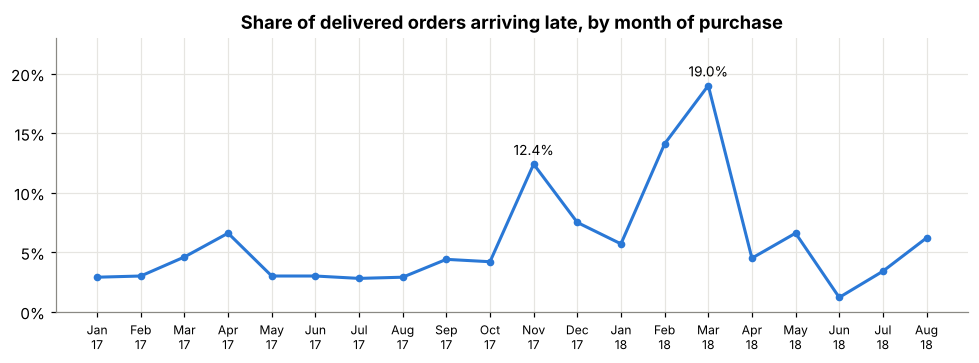

,orders,late_pct
month,,
2017-01,750,2.900
2017-02,1653,3.000
2017-03,2546,4.600
2017-04,2303,6.600
2017-05,3545,3.000
2017-06,3135,3.000
2017-07,3872,2.800
2017-08,4193,2.900
2017-09,4150,4.400


In [6]:
monthly = (d.assign(month=d["purchase_date"].dt.to_period("M")).groupby("month")
             .agg(orders=("late", "size"), late_pct=("late", "mean")))
monthly["late_pct"] = (100 * monthly["late_pct"]).round(1)
monthly = monthly[monthly["orders"] >= 500]
monthly.index = monthly.index.astype(str)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(monthly.index, monthly["late_pct"], color=BLUE, lw=2, marker="o", ms=4)
ax.set_ylim(0, 23); ax.yaxis.set_major_locator(mtick.MultipleLocator(5)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xticks(range(len(monthly))); ax.set_xticklabels(pd.PeriodIndex(monthly.index, freq="M").strftime("%b\n%y"), fontsize=8)
for m in ["2017-11", "2018-03"]:
    i = list(monthly.index).index(m)
    ax.annotate(f"{monthly.loc[m, 'late_pct']:.1f}%", (i, monthly.loc[m, "late_pct"]), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=9)
ax.set_title("Share of delivered orders arriving late, by month of purchase")
fig.tight_layout(); fig.savefig("images/late_by_month.png"); plt.show()
monthly

## 5. Where: late deliveries by state

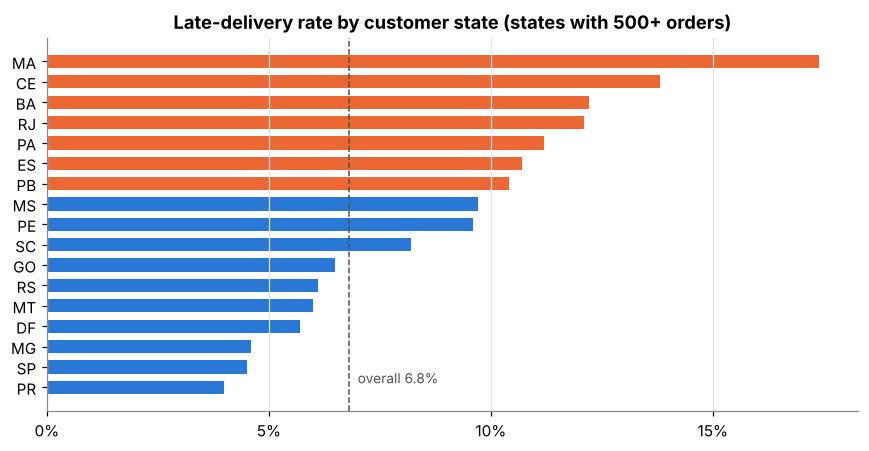

,customer_state,orders,late_pct,avg_days_to_deliver
0,MA,717,17.400,21.600
1,CE,1279,13.800,21.300
2,BA,3256,12.200,19.300
3,RJ,12350,12.100,15.300
4,PA,946,11.200,23.800
5,ES,1995,10.700,15.800
6,PB,517,10.400,20.400
7,MS,701,9.700,15.600
8,PE,1593,9.600,18.400
9,SC,3546,8.200,15.000


In [7]:
states = pd.read_sql(QUERIES["late_rate_by_state"], con)
fig, ax = plt.subplots(figsize=(8, 4.2))
s = states.sort_values("late_pct")
ax.barh(s["customer_state"], s["late_pct"], color=[ORANGE if v >= 10 else BLUE for v in s["late_pct"]], height=0.65)
ax.axvline(headline["late_pct"], color="#52514e", lw=1, ls="--")
ax.text(headline["late_pct"] + 0.2, 0.2, f"overall {headline['late_pct']}%", fontsize=9, color="#52514e")
ax.xaxis.set_major_locator(mtick.MultipleLocator(5)); ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis="y", visible=False)
ax.set_title("Late-delivery rate by customer state (states with 500+ orders)")
fig.tight_layout(); fig.savefig("images/late_by_state.png"); plt.show()
states

## Findings

| Measure | Value |
|---|---|
| Delivered orders | 96,470 |
| Arrived after the promised date | 6,534 (6.8%) |
| Median delivery time | 10.2 days |
| Median order arrived | 12 days before its estimate |
| Average review: on time / late | 4.29 / 2.27 stars |

1. **Lateness wrecks reviews, fast.** Orders arriving 1 to 3 days late already average 3.29 stars against 4.29 on time. At 8 or more days late the average is 1.70, and 69.8% of those reviews are one star.
2. **Late orders are a small share of orders but a large share of complaints.** They are 6.8% of deliveries but 36.7% of all one-star reviews. If late orders were reviewed like on-time ones, the platform average would be 4.29 instead of 4.16.
3. **The estimates are already generous and still missed.** The typical order arrives 12 days early, so the problem is the tail of very slow deliveries, not the typical one.
4. **Lateness spikes at peaks.** 12.4% of orders placed in November 2017, the month of Black Friday, arrived late, and 14.1% and 19.0% in February and March 2018, against about 3% in a normal month in mid-2017.
5. **Some regions are badly served.** Maranhão (17.4%), Ceará (13.8%) and Bahia (12.2%) have the highest late rates. Rio de Janeiro (12.1%) matters most because of its volume: 12,350 orders. São Paulo, the largest market, is at 4.5% with deliveries averaging 8.8 days.

**What I would recommend:** set promised dates by destination state and season instead of one rule, add courier capacity ahead of Black Friday and other peaks, and message customers proactively when an order is running late.

**Limitations.** One Brazilian marketplace, 2016 to 2018. Lateness and low reviews are strongly associated, but some late orders may also have had other problems (wrong item, damage) that lowered the score.

In [8]:
summary = {
    "checks": {k: int(v) for k, v in checks.items()},
    "headline": headline,
    "by_band": [{"band": str(k), "orders": int(v["orders"]), "avg_review": float(v["avg_review"]), "one_star_pct": float(v["one_star_pct"])} for k, v in by_band.iterrows()],
    "monthly": [{"month": k, "orders": int(v["orders"]), "late_pct": float(v["late_pct"])} for k, v in monthly.iterrows()],
    "states": states.to_dict(orient="records"),
}
json.dump(summary, open("results/summary.json", "w"), indent=1)
print("saved results/summary.json")

saved results/summary.json
